# Does Ramen's update point toward the true class? Cosine with the oracle cross-entropy gradient (EuroSAT)

**Question.** Ramen adapts each test image with one SignSGD step along $\hat g_i$, a weighted average of *entropy*
gradients retrieved from its memory. Entropy minimisation sharpens whatever the model already predicts, right or
wrong. How close is $\hat g_i$ to the direction we would really want, the gradient of the **cross-entropy toward the
true label** $g^{CE}_i$? We measure the cosine similarity between the two for every test image.

**This is an oracle measurement, not a method.** $g^{CE}_i$ uses the ground-truth label, which a real test-time
method never has. The probe only *observes*: Ramen's predictions are unchanged (checked in section 3).

**Hypotheses (pre-registered in `ga_configs.py` before the full run).**
- **H1** Ramen's update carries image-specific information about the true class: median $\cos(\hat g_i, g^{CE}_i)$ is
  above the shuffled control $\cos(\hat g_i, g^{CE}_j)$, $j$ another image of the same batch.
- **H2** Memory helps where zero-shot is wrong: on zero-shot-wrong images, median $\cos(\hat g_i, g^{CE}_i)$ is above
  median $\cos(g_i, g^{CE}_i)$, with $g_i$ the image's own entropy gradient (pilot on 100 DomainNet images: mean
  $-0.31$ on the 38 wrong ones).
- **H3** Alignment explains outcomes: (a) among zero-shot-wrong images, the share Ramen fixes rises with
  $\cos(\operatorname{sign} \hat g_i, g^{CE}_i)$; (b) images Ramen breaks have a median
  $\cos(\operatorname{sign} \hat g_i, g^{CE}_i) < 0$.

**Why this test.** It asks directly whether Ramen's direction is "correct", using the cheapest possible oracle:
one extra backward pass per batch on a run that is otherwise Ramen itself.

**Runs.**

| Run | What it does | Uses true labels? |
|---|---|---|
| `NoAdapt` | zero-shot CLIP (cached) | no |
| `Ramen` | Ramen (cached) | no |
| `ga_probe` | Ramen + per-image gradient probe (`RamenGradientProbe`); predictions = Ramen's | **yes, only to measure** |

**Data.** EuroSAT, 27,000 satellite images, 1 domain, 10 classes; CLIP ViT-B/16; `cfg/EuroSAT/Ramen.yaml`: $K = 7{,}500$, $k = 50$, $\beta = 5$, $\eta = 0.01$. Mixed stream (all domains shuffled together), batch size 100.

**Seeds.** Seed 0 only (a seed sets the stream order). No accuracy changes here, so the noise floor does not apply;
all numbers are descriptive, from one stream.

**How the runs were produced.**
`CUDA_VISIBLE_DEVICES=0 python run_grad_alignment.py EuroSAT 0` (after `--smoke smoke` on 200 images per domain, and
`check_gradients.py`). Results: `new_experiments/results/EuroSAT_*_s0_ga_probe.pkl` and `_stats.pkl` (per-image probe
log).

**What counts as a result.** The four pre-registered tests (section 6), plus the descriptive figures.

**Sections.** 1 Setup · 2 Data · 3 Sanity and correctness · 4 Results · 5 Mechanism · 6 Hypotheses ·
7 Interpretation · 8 Glossary


## Method: what is measured

**Ramen (unchanged; notation shared by all Ramen notebooks).** Batch $x_1, \dots, x_B$ ($B = 100$); $\theta_0$ = the
affine weights and biases of every LayerNorm in the CLIP image encoder ($D = 39{,}936$ numbers), one copy per image.
$w_c$ = normalised text embedding of class $c$.
$$z_i = \frac{f_{\theta_0}(x_i)}{\lVert f_{\theta_0}(x_i) \rVert}, \quad
p_i = \operatorname{softmax}(100\, z_i^\top W), \quad \hat y_i = \arg\max_c p_{ic}, \quad
H_i = -\textstyle\sum_c p_{ic} \log p_{ic}, \quad g_i = \nabla_\theta H_i \big|_{\theta_0}$$
1. *Write* $(z_i, g_i, H_i)$ into queue $\mathcal M_{\hat y_i}$ (capacity $K$), **before** retrieval.
2. *Retrieve* from every non-empty queue $c \in C$ the $k$ entries nearest to $z_i$, $\mathcal N_k^c(z_i)$.
3. *Aggregate* $\displaystyle \hat g_i = \frac{1}{|C|} \sum_{c \in C} \sum_{j \in \mathcal N_k^c(z_i)}
   e^{-H_j} e^{-\beta d_{ij}}\, g_j$, with $d_{ij} = \lVert z_i - z_j \rVert$.
4. *Update* $\theta_i = \theta_0 - \eta\, \operatorname{sign}(\hat g_i)$, predict with $\theta_i$, reset to $\theta_0$.

**The oracle direction** (uses the true label $y_i$ — ground truth, available only in this experiment):
$$g^{CE}_i = \nabla_\theta \big[-\log p_{i y_i}\big]\Big|_{\theta_0}$$
the gradient of the cross-entropy toward the true class at the same unadapted parameters. Stepping along
$-g^{CE}_i$ raises $p_{i y_i}$ fastest.

**Measured per image.**
- $\cos(\hat g_i, g^{CE}_i)$: alignment of Ramen's update. **Positive = moving against $\hat g_i$ also lowers the
  true-label loss** (both are descent directions, so the sign convention matches).
- $\cos(\operatorname{sign} \hat g_i, g^{CE}_i)$: alignment of the step Ramen actually takes. To first order,
  $$\mathrm{CE}(\theta_i) - \mathrm{CE}(\theta_0) \approx -\eta\, \operatorname{sign}(\hat g_i)^\top g^{CE}_i
  = -\eta \sqrt D\, \lVert g^{CE}_i \rVert\, \cos(\operatorname{sign} \hat g_i, g^{CE}_i),$$
  so a positive value means the step lowers the true-label loss.
- Sign agreement $A_i = \sum_t |g^{CE}_{it}|\, \mathbb 1[\operatorname{sign} \hat g_{it} = \operatorname{sign} g^{CE}_{it}]
  / \sum_t |g^{CE}_{it}|$: the share of the oracle gradient's mass on coordinates the step moves the right way
  (0.5 = random signs).
- **Reference** $\cos(g_i, g^{CE}_i)$: the image's own entropy gradient, i.e. per-image entropy minimisation with no
  memory.
- **Control** $\cos(\hat g_i, g^{CE}_{\pi(i)})$, $\pi(i) = i - 1 \bmod B$ (another image of the same batch): how much
  alignment any update gets just from directions shared by all images.

**Where the alignment comes from.** $\hat g_i$ is a sum of per-queue terms, so it splits exactly into four parts,
$\hat g_i = s_i + t_i + u_i + o_i$:
$s_i$ = the image's **own entry** (written before retrieval, found at distance $\approx 0$, so
$s_i \approx e^{-H_i} g_i / |C|$; zero if it was not stored), $t_i$ = the other entries of the **true-class queue**
$\mathcal M_{y_i}$, $u_i$ = the other entries of the **zero-shot-class queue** $\mathcal M_{\hat y_i}$ when
$\hat y_i \ne y_i$ (else 0), $o_i$ = **all other queues**. Then
$$\cos(\hat g_i, g^{CE}_i) = \sum_{v \in \{s, t, u, o\}} \frac{\langle v_i, g^{CE}_i \rangle}
{\lVert \hat g_i \rVert\, \lVert g^{CE}_i \rVert}.$$

| Symbol | Meaning | Code | Value here |
|---|---|---|---|
| $g^{CE}_i$ | true-label CE gradient (**oracle**) | `RamenGradientProbe.oracle_ce_gradient` | — |
| $\hat g_i$ | Ramen's update | `RamenTrueLabel.retrieve` (= Ramen's) | — |
| $g_i$ | own entropy gradient | `get_by_sample_grad()` after Ramen's entropy backward | — |
| $s, t, u, o$ | parts of $\hat g_i$ | `RamenGradientProbe.decompose` / `queue_part` | — |
| cosines, $A_i$ | per-image metrics | `alignment.py`; logged as `cos_update`, `cos_step`, `agree_step`, `cos_self`, `cos_update_shuffled`, `part_*` | — |
| $K, k, \beta, \eta$ | Ramen's settings | `max_capacity`, `topk`, `beta`, `lr` | 7500, 50, 5, 0.01 |


## 1. Setup

In [1]:
import os
import warnings
warnings.filterwarnings('ignore', message='IProgress not found')
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '')   # analysis only: everything is loaded from cached results
import pandas as pd
from IPython.display import display

from ga_experiment import GradAlignmentExperiment
from ga_analysis import (data_table, outcome_table, direction_summary, decomposition, binned_outcome_rates,
                         hypotheses, memory_freeze_position)
from ga_plots import (plot_cosine_distributions, plot_outcome_dumbbell, plot_domain_dumbbell, plot_stream,
                      plot_decomposition, plot_outcome_vs_alignment)

pd.set_option('display.width', 200, 'display.max_columns', 30)
DATASET = 'EuroSAT'
e = GradAlignmentExperiment(DATASET, seed=0).run_all()   # cached NoAdapt, Ramen and ga_probe
df = e.frame()                                            # one row per image
print(f'{len(df):,} images loaded')

27,000 images loaded


## 2. The data the code ran on

Counts are images; "fixed" = zero-shot wrong and Ramen right, "broken" = zero-shot right and Ramen wrong.
Accuracy here is **pooled over images** (not domain-averaged), because the cosines are per image. Zero-shot = the
prediction Ramen filed each image under (logged by the probe).

In [2]:
display(data_table(df))
display(outcome_table(df))

,images,classes,zero-shot correct,Ramen correct,fixed by Ramen,broken by Ramen
domain,,,,,,
satellite,27000,10,"12,984 of 27,000 (48.1%)","16,910 of 27,000 (62.6%)","5,008 of 27,000 (18.5%)","1,082 of 27,000 (4.0%)"
all (pooled),27000,10,"12,984 of 27,000 (48.1%)","16,910 of 27,000 (62.6%)","5,008 of 27,000 (18.5%)","1,082 of 27,000 (4.0%)"


,images,share,meaning
both right,11902,44.1%,"zero-shot right, Ramen right"
fixed by Ramen,5008,18.5%,"zero-shot wrong, Ramen right"
broken by Ramen,1082,4.0%,"zero-shot right, Ramen wrong"
both wrong,9008,33.4%,"zero-shot wrong, Ramen wrong"


## 3. Sanity and correctness

1. The probe must not change Ramen: identical predictions on every image of the stream.
2. Zero-shot predictions inside Ramen vs the cached NoAdapt run (another code path; fp16 near-ties can differ).
3. `check_gradients.py` (log below): G1 the batched per-image CE gradient equals the gradient of the image computed
   alone; G2 a step along $-\operatorname{sign}(g^{CE})$ raises p(true class); G3 the four parts sum back to Ramen's
   update; G4 the own-entry part is non-zero exactly when the entry was stored.

In [3]:
assert e.sanity_check(), 'the probe changed Ramen\'s predictions'
print(f'zero-shot prediction differs from the cached NoAdapt run on {e.zs_mismatch:,} of {len(df):,} images '
      f'({e.zs_mismatch / len(df):.3%})')
log = f'logs/check_gradients_{DATASET}.log'
print(open(log).read() if os.path.exists(log) else f'{log} missing: run check_gradients.py {DATASET}')

EuroSAT: same stream as Ramen: True; ga_probe == Ramen on 27,000 of 27,000 images (100.00%)
zero-shot prediction differs from the cached NoAdapt run on 93 of 27,000 images (0.344%)
EuroSAT: 1 domains x 200 images, 10 classes, model=clip_vitbase16, mode=mixed
  G1 image 0: cos(batched row, alone) = 0.999994, relative error 6.75e-03
  G1 image 1: cos(batched row, alone) = 0.999964, relative error 9.13e-03
  G1 image 2: cos(batched row, alone) = 0.999984, relative error 6.20e-03
  G1 image 3: cos(batched row, alone) = 0.999976, relative error 1.98e-02
  G2 step along -sign(g_ce): p(true) rises on 98 of 100 images, mean +0.4699
  G3 10 non-empty queues: max relative error |sum of parts - update| / |update| = 2.63e-04; min cos = 1.000000
  G4 own entry stored for 100 of 100; part_self non-zero for 100; same images: True; min cos(part_self, own entropy gradient) = 1.000000
G1: PASS
G2: PASS
G3: PASS
G4: PASS



## 4. Results

### 4.1 How aligned is Ramen's update with the true-label gradient?

Each panel is one group of images; each curve is one direction compared with $g^{CE}$. Blue = Ramen's update,
orange = the image's own entropy gradient (no memory), grey = control (another image's $g^{CE}$).

,images,own entropy gradient (no memory),Ramen's update,control: another image's CE gradient,Ramen's sign step,sign agreement (step),sign agreement (own entropy),update cos > 0
zs_ok,,,,,,,,
zero-shot right,12984,0.974,0.49,0.156,0.182,0.758,0.985,"12,645 of 12,984 (97.4%)"
zero-shot wrong,14016,-0.244,0.10,0.148,0.038,0.556,0.402,"8,749 of 14,016 (62.4%)"


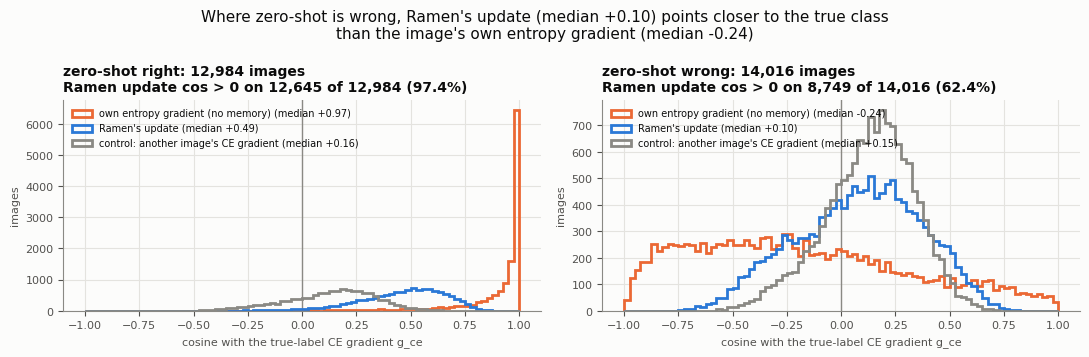

In [4]:
plot_cosine_distributions(df);
display(direction_summary(df, df['zs_ok'].map({True: 'zero-shot right', False: 'zero-shot wrong'})).round(3))

### 4.2 By outcome: images Ramen fixes, breaks, or leaves

Dumbbell per outcome group: orange = median cosine of the image's own entropy gradient, blue = of Ramen's update,
grey diamond = control. The line between them is what the memory changes.

,images,own entropy gradient (no memory),Ramen's update,control: another image's CE gradient,Ramen's sign step,sign agreement (step),sign agreement (own entropy),update cos > 0
outcome,,,,,,,,
both right,11902,0.979,0.506,0.156,0.188,0.767,0.988,"11,801 of 11,902 (99.2%)"
fixed by Ramen,5008,-0.212,0.267,0.145,0.089,0.632,0.421,"4,373 of 5,008 (87.3%)"
broken by Ramen,1082,0.747,0.201,0.159,0.068,0.595,0.862,"844 of 1,082 (78.0%)"
both wrong,9008,-0.259,-0.009,0.149,-0.001,0.498,0.389,"4,376 of 9,008 (48.6%)"


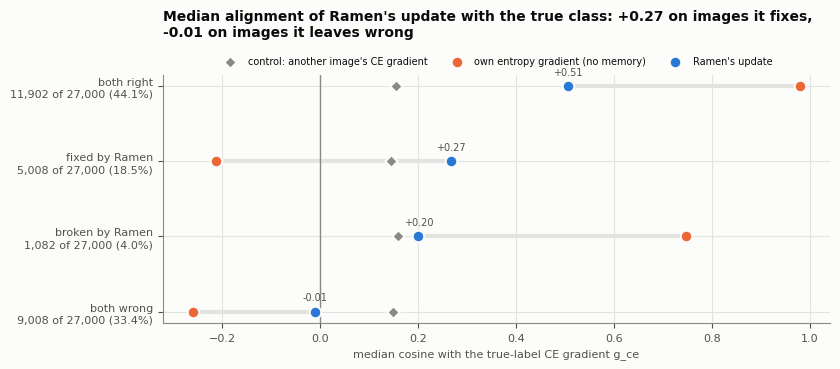

In [5]:
plot_outcome_dumbbell(df);
display(direction_summary(df, 'outcome').round(3))

### 4.3 By domain

One domain only, so this is the same as section 4.1; skipped.

### 4.4 Over the stream

Rolling mean over stream position. The dashed line marks where fewer than half of the images still get their own
entry stored (Ramen's fp16 arrival counter saturates after 65,520 inserts and full queues stop updating).

memory never freezes


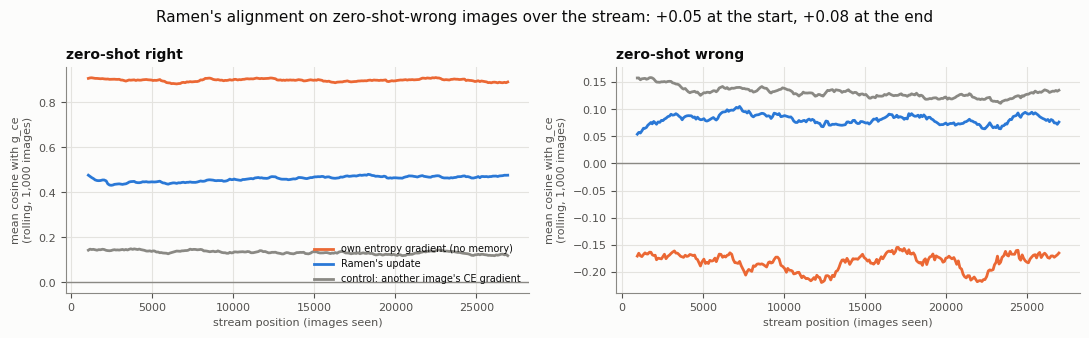

In [6]:
freeze = memory_freeze_position(df)
print(f'own entry stored for {int((df.part_self != 0).sum()):,} of {len(df):,} images; '
      f'mostly frozen from position {freeze:,}' if freeze else 'memory never freezes')
plot_stream(df, window=1_000, freeze_at=freeze);

## 5. Mechanism

### 5.1 Which memory entries make the update aligned?

The alignment $\cos(\hat g_i, g^{CE}_i)$ split exactly into the four parts of the update (section "Method"):
the image's own entry, other entries of the true-class queue, other entries of the wrong zero-shot-class queue, and
all other queues. Bars are means over images; the black tick is the total.

,images,part_self,part_true,part_zs,part_other,cos_update
outcome,,,,,,
both right,11902,0.095,0.293,0.000,0.098,0.486
fixed by Ramen,5008,-0.007,0.181,-0.023,0.106,0.257
broken by Ramen,1082,0.033,0.119,0.000,0.045,0.197
both wrong,9008,-0.020,0.069,-0.034,-0.031,-0.017


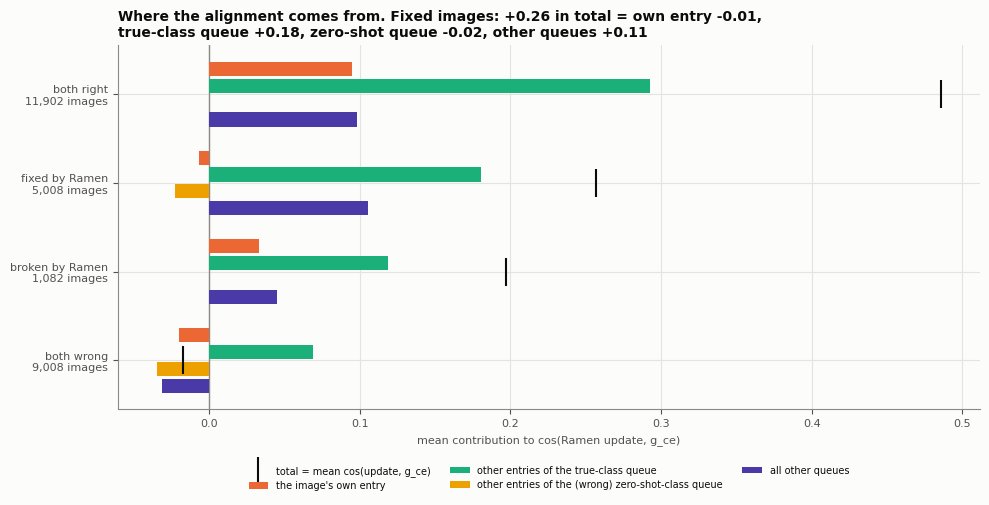

In [7]:
display(decomposition(df).round(3))
plot_decomposition(df);

### 5.2 Does alignment predict whether Ramen fixes or breaks an image?

Images are split into deciles of $\cos(\operatorname{sign} \hat g_i, g^{CE}_i)$ (the step Ramen takes) within each
zero-shot group. Left: share of zero-shot errors Ramen fixes; middle: share of zero-shot hits it breaks; right:
median change of $\log p(y_i)$ caused by the step. Counts in the end labels.

,group,bin,x,images,events,rate,dlogp_median
0,zero-shot right,"(-0.176, 0.075]",0.040,1299,578,0.445,0.001
1,zero-shot right,"(0.075, 0.116]",0.098,1298,209,0.161,0.350
2,zero-shot right,"(0.116, 0.142]",0.130,1298,123,0.095,0.439
3,zero-shot right,"(0.142, 0.164]",0.153,1299,70,0.054,0.398
4,zero-shot right,"(0.164, 0.182]",0.173,1298,51,0.039,0.356
5,zero-shot right,"(0.182, 0.197]",0.190,1298,23,0.018,0.288
6,zero-shot right,"(0.197, 0.212]",0.205,1299,15,0.012,0.246
7,zero-shot right,"(0.212, 0.228]",0.220,1298,5,0.004,0.205
8,zero-shot right,"(0.228, 0.247]",0.237,1298,8,0.006,0.184
9,zero-shot right,"(0.247, 0.355]",0.262,1299,0,0.000,0.173


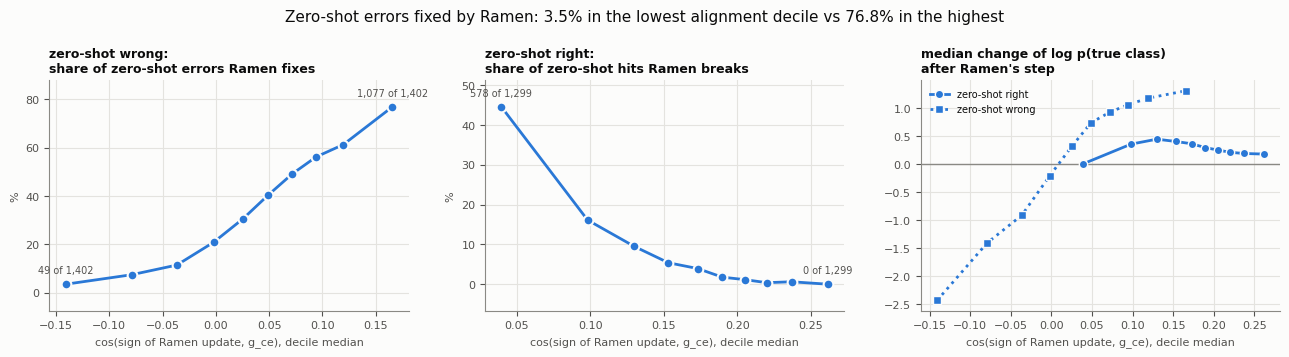

In [8]:
plot_outcome_vs_alignment(df);
display(binned_outcome_rates(df).round(3))

## 6. Pre-registered hypotheses

In [9]:
display(hypotheses(df))

,test,numbers,holds
hypothesis,,,
H1,"median cos(update, g_ce) > median control cos(...",+0.310 vs +0.152,True
H2,"zero-shot wrong: median cos(update, g_ce) > me...","+0.100 vs -0.244 (14,016 images)",True
H3a,zero-shot wrong: fix rate rises with cos(sign ...,fix rate 3.5% (lowest bin) -> 76.8% (highest);...,True
H3b,"images Ramen breaks: median cos(sign step, g_c...","+0.068 (1,082 images; zero-shot right overall ...",False


## 7. Interpretation (EuroSAT, seed 0, 27,000 images)

**In one line.** With only 10 classes, Ramen's memory *does* point toward the true class. On zero-shot-wrong images
the update goes from −0.24 (own entropy gradient) to +0.10. The images Ramen fixes get their alignment mainly from
the true-class queue (+0.18 of +0.26). It is still below the shuffled control (+0.15) on zero-shot-wrong images as a
whole.

**What the numbers show.**
- **Zero-shot right (12,984 images, 48.1%).** Own entropy gradient 0.97, Ramen's update 0.49 (positive on 12,645 of
  12,984 = 97.4%), far above the control (+0.16). Breaks: 1,082 (8.3% of these images).
- **Zero-shot wrong (14,016 images, 51.9%).** Own entropy gradient −0.24, Ramen's update +0.10 (positive on 8,749
  of 14,016 = 62.4%). The sign step agrees with the oracle on 55.6% of its gradient mass, the clearest above-chance
  value of the three datasets. H2 holds. The update stays below the control (+0.148). The control is high on
  EuroSAT because with 10 classes another image's CE gradient often shares this image's class or the common
  "sharpen" direction.
- **Fixed (5,008) vs broken (1,082).** Fixed images had a *wrong* own direction (−0.21) that Ramen *reversed*
  (+0.27; positive on 4,373 of 5,008 = 87.3%). That is real redirection, which DomainNet and ImageNet-C did not
  show. Broken images lose part of a good own direction (+0.75 → +0.20) but stay positive (sign step +0.068), so
  H3b fails here too.
- **Alignment decides the outcome (H3a).** The fix rate rises from 3.5% (49 of 1,402) in the lowest decile to 76.8%
  (1,077 of 1,402) in the highest. The break rate falls from 44.5% (578 of 1,299) to 0.0% (0 of 1,299).
- **Where the alignment comes from.** Fixed images: +0.257 in total, of which true-class queue +0.181, other queues
  +0.106, zero-shot queue −0.023, own entry −0.007. Over all zero-shot-wrong images: true-class queue +0.109 of
  +0.081 in total. With 10 queues, the true class gets 1/10 of the update instead of 1/345 (DomainNet) or 1/974
  (ImageNet-C). Correctly filed same-class images then pull the update toward the true class. This fits the
  label-value oracle's large EuroSAT gain (+26.70).
- **Over the stream.** Flat: about +0.47 on zero-shot-right images and +0.05 → +0.08 on zero-shot-wrong images.
  The memory never fills (7,500 per queue) and never freezes: own entry stored for all 27,000 images.

**What this does not show.**
- One seed. EuroSAT is the noisiest dataset in the project (Ramen's noise floor is several points), so the size of
  each number is less certain than on the large datasets.
- Why fixes still need above-control alignment. On zero-shot-wrong images as a whole the update is below the
  control, so the true-class pull is enough only on the 36% of errors that Ramen fixes.
- Zero-shot = the prediction Ramen filed each image under. It differs from the cached NoAdapt run on 93 of 27,000
  images (0.34%, fp16 near-ties).

**Next step.** Compare across datasets (README). Weighting the true-class queue more works on EuroSAT because of
its few classes; the open question is how to find that queue without labels on 345 or 1,000 classes.


## 8. Glossary

| Term | Meaning |
|---|---|
| Ramen | Test-time adaptation for CLIP: per-class memory of past images' entropy gradients; each image takes one SignSGD step along a weighted average of retrieved gradients, predicts, and resets |
| zero-shot | CLIP's prediction without adaptation ($\hat y_i$); Ramen files each image in this class's queue |
| $g^{CE}$ (oracle gradient) | gradient of the cross-entropy toward the **true** label; uses ground truth, so it is a measuring stick, not something a method can use |
| own entropy gradient $g_i$ | gradient of the image's own prediction entropy; minimising it sharpens the current prediction, right or wrong |
| Ramen's update $\hat g_i$ | the retrieved, weighted average of stored entropy gradients that Ramen steps along |
| sign step | Ramen moves by $-\eta\,\mathrm{sign}(\hat g_i)$, so only the sign of each coordinate matters for the step |
| cosine similarity | $\langle a, b\rangle / (\lVert a\rVert \lVert b\rVert)$, from −1 (opposite) through 0 (unrelated) to +1 (same direction) |
| sign agreement | share of $\lvert g^{CE}\rvert$ mass on coordinates where the sign step moves the same way as the oracle; 0.5 = chance |
| shuffled control | cosine of an image's update with *another* image's $g^{CE}$; alignment shared by all images, not specific to the true class |
| own entry | the image's own memory entry, written before retrieval and retrieved at distance ≈ 0 |
| fixed / broken | zero-shot wrong → Ramen right / zero-shot right → Ramen wrong |
| fp16 freeze | Ramen's arrival counter is stored in fp16 and saturates after 65,520 images; full queues then stop accepting new entries |
| pooled accuracy | correct images / all images (here), as opposed to the domain-averaged accuracy used for headline numbers |
